# Olist EDA and Data Cleaning

This notebook first checks the raw data, then applies basic cleaning rules and saves the results with their original file names.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')

## 1. Read the raw files

In [2]:
raw_path = Path(r'C:/Users/ahmed/Desktop/final_project_DEPI/Raw_Data')
save_path = Path(r'C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data')

customers = pd.read_csv(raw_path / 'olist_customers_dataset.csv')
geolocation = pd.read_csv(raw_path / 'olist_geolocation_dataset.csv')
orders = pd.read_csv(raw_path / 'olist_orders_dataset.csv')
order_items = pd.read_csv(raw_path / 'olist_order_items_dataset.csv')
order_payments = pd.read_csv(raw_path / 'olist_order_payments_dataset.csv')
order_reviews = pd.read_csv(raw_path / 'olist_order_reviews_dataset.csv')
products = pd.read_csv(raw_path / 'olist_products_dataset.csv')
sellers = pd.read_csv(raw_path / 'olist_sellers_dataset.csv')
translation = pd.read_csv(raw_path / 'product_category_name_translation.csv')

## 2. Inspect all tables

In [3]:
tables = {
    'customers': customers,
    'geolocation': geolocation,
    'orders': orders,
    'order_items': order_items,
    'order_payments': order_payments,
    'order_reviews': order_reviews,
    'products': products,
    'sellers': sellers,
    'translation': translation
}

for name, table in tables.items():
    print('\n', name, table.shape)
    print('Duplicates:', table.duplicated().sum())
    print('Missing values:')
    print(table.isnull().sum())
    numerical_columns = table.select_dtypes(include='number').columns.tolist()
    categorical_columns = table.select_dtypes(include='object').columns.tolist()
    print('Numerical columns:', numerical_columns)
    print('Categorical columns:', categorical_columns)


 customers (99441, 5)
Duplicates: 0
Missing values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64
Numerical columns: ['customer_zip_code_prefix']
Categorical columns: ['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']

 geolocation (1000163, 5)


C:\Users\ahmed\AppData\Local\Temp\ipykernel_24904\3146178609.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = table.select_dtypes(include='object').columns.tolist()


Duplicates: 261831
Missing values:
geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64
Numerical columns: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng']
Categorical columns: ['geolocation_city', 'geolocation_state']

 orders (99441, 8)


C:\Users\ahmed\AppData\Local\Temp\ipykernel_24904\3146178609.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = table.select_dtypes(include='object').columns.tolist()
C:\Users\ahmed\AppData\Local\Temp\ipykernel_24904\3146178609.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pyd

Duplicates: 0
Missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
Numerical columns: []
Categorical columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

 order_items (112650, 7)
Duplicates: 0
Missing values:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
Numerical columns: ['order_item_id', 'price', 'freight_value']
Categorical columns: ['order_id', 'product_id', 'seller_id', 'shipping_limit_date']

 order_payments (103886, 5)

C:\Users\ahmed\AppData\Local\Temp\ipykernel_24904\3146178609.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = table.select_dtypes(include='object').columns.tolist()
C:\Users\ahmed\AppData\Local\Temp\ipykernel_24904\3146178609.py:19: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pyd

## 3. View rows and summary statistics

In [4]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
orders.tail()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00
99440,66dea50a8b16d9b4dee7af250b4be1a5,edb027a75a1449115f6b43211ae02a24,delivered,2018-03-08 20:57:30,2018-03-09 11:20:28,2018-03-09 22:11:59,2018-03-16 13:08:30,2018-04-03 00:00:00


In [6]:
for name, table in tables.items():
    print('\n', name)
    print(table.describe(include='all').T)


 customers
                            count unique                               top  \
customer_id                 99441  99441  06b8999e2fba1a1fbc88172c00ba8bc7   
customer_unique_id          99441  96096  8d50f5eadf50201ccdcedfb9e2ac8455   
customer_zip_code_prefix  99441.0    NaN                               NaN   
customer_city               99441   4119                         sao paulo   
customer_state              99441     27                                SP   

                           freq          mean           std     min      25%  \
customer_id                   1           NaN           NaN     NaN      NaN   
customer_unique_id           17           NaN           NaN     NaN      NaN   
customer_zip_code_prefix    NaN  35137.474583  29797.938996  1003.0  11347.0   
customer_city             15540           NaN           NaN     NaN      NaN   
customer_state            41746           NaN           NaN     NaN      NaN   

                              50%     

## 4. Check categories, invalid values, and outliers

In [7]:
print('Order statuses:')
print(orders['order_status'].value_counts(dropna=False))
print('Payment types:')
print(order_payments['payment_type'].value_counts(dropna=False))
print('Review scores:')
print(order_reviews['review_score'].value_counts(dropna=False).sort_index())
print('Top product categories:')
print(products['product_category_name'].value_counts().head(10))
print('Negative prices:', (order_items['price'] < 0).sum())
print('Negative freight:', (order_items['freight_value'] < 0).sum())
print('Review scores outside 1 to 5:', (~order_reviews['review_score'].between(1, 5)).sum())

q1 = order_items['price'].quantile(0.25)
q3 = order_items['price'].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)
print('Prices above the IQR limit:', (order_items['price'] > upper_limit).sum())

Order statuses:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
Payment types:
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64
Review scores:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64
Top product categories:
product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64
Negative prices: 0
Negative freight: 0
Review scores outside 1 to 5: 0
Prices above the IQR limit: 8427


## 5. EDA charts

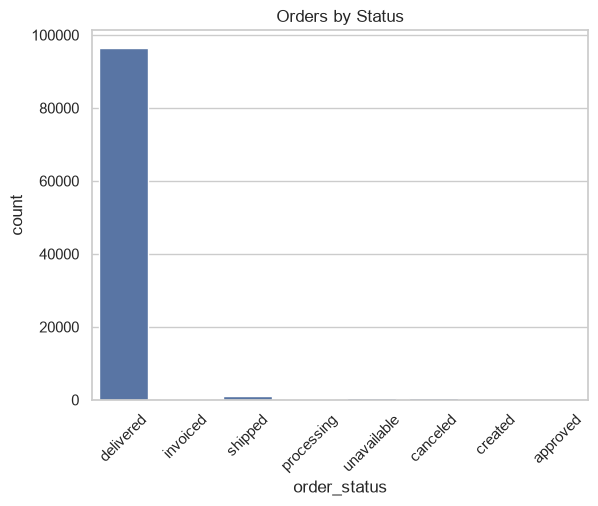

In [8]:
sns.countplot(data=orders, x='order_status')
plt.xticks(rotation=45)
plt.title('Orders by Status')
plt.show()

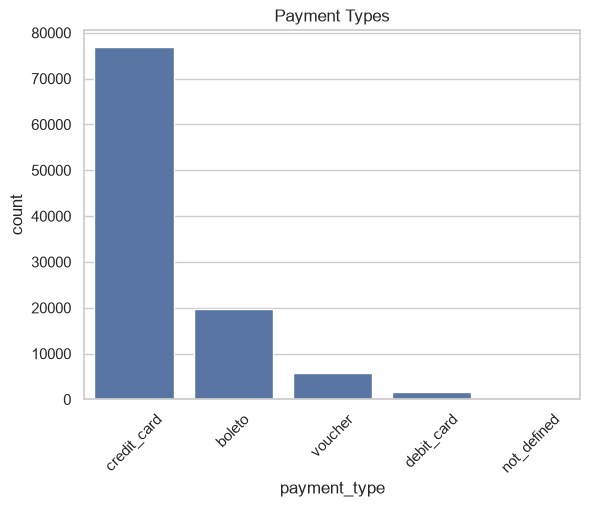

In [9]:
sns.countplot(data=order_payments, x='payment_type')
plt.xticks(rotation=45)
plt.title('Payment Types')
plt.show()

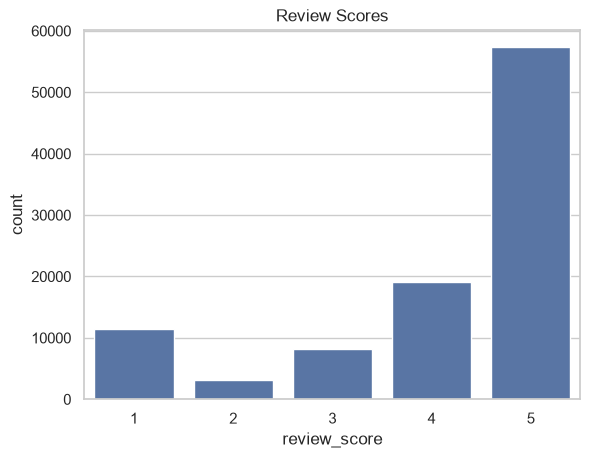

In [10]:
sns.countplot(data=order_reviews, x='review_score')
plt.title('Review Scores')
plt.show()

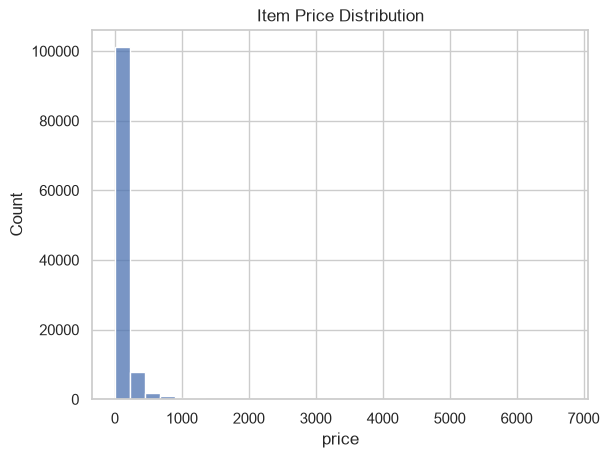

In [11]:
sns.histplot(data=order_items, x='price', bins=30)
plt.title('Item Price Distribution')
plt.show()

## 6. Clean the data

In [12]:
for table in tables.values():
    table.drop_duplicates(inplace=True)

    numerical_columns = table.select_dtypes(include='number').columns
    table[numerical_columns] = table[numerical_columns].fillna(table[numerical_columns].median())

    categorical_columns = table.select_dtypes(include='object').columns
    table[categorical_columns] = table[categorical_columns].fillna('Unknown')
    table[categorical_columns] = table[categorical_columns].apply(lambda column: column.str.strip())

orders['order_status'] = orders['order_status'].str.lower()
order_payments['payment_type'] = order_payments['payment_type'].str.lower()

date_columns = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], errors='coerce')

order_items['shipping_limit_date'] = pd.to_datetime(order_items['shipping_limit_date'], errors='coerce')
order_reviews['review_creation_date'] = pd.to_datetime(order_reviews['review_creation_date'], errors='coerce')
order_reviews['review_answer_timestamp'] = pd.to_datetime(order_reviews['review_answer_timestamp'], errors='coerce')

C:\Users\ahmed\AppData\Local\Temp\ipykernel_24904\4161517674.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = table.select_dtypes(include='object').columns
C:\Users\ahmed\AppData\Local\Temp\ipykernel_24904\4161517674.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/doc

## 7. Validate and save the cleaned files

In [13]:
for name, table in tables.items():
    print(name, 'rows and columns:', table.shape)
    print('Remaining missing values:', table.isnull().sum().sum())
    print('Remaining duplicate rows:', table.duplicated().sum())

print('Duplicate review IDs:', order_reviews['review_id'].duplicated().sum())
print('Duplicate order IDs in reviews:', order_reviews['order_id'].duplicated().sum())
print('Repeated geolocation ZIP prefixes:', geolocation['geolocation_zip_code_prefix'].duplicated().sum())

customers rows and columns: (99441, 5)
Remaining missing values: 0
Remaining duplicate rows: 0
geolocation rows and columns: (738332, 5)
Remaining missing values: 0
Remaining duplicate rows: 0
orders rows and columns: (99441, 8)
Remaining missing values: 4908
Remaining duplicate rows: 0
order_items rows and columns: (112650, 7)
Remaining missing values: 0
Remaining duplicate rows: 0
order_payments rows and columns: (103886, 5)
Remaining missing values: 0
Remaining duplicate rows: 0
order_reviews rows and columns: (99224, 7)
Remaining missing values: 0
Remaining duplicate rows: 0
products rows and columns: (32951, 9)
Remaining missing values: 0
Remaining duplicate rows: 0
sellers rows and columns: (3095, 4)
Remaining missing values: 0
Remaining duplicate rows: 0
translation rows and columns: (71, 2)
Remaining missing values: 0
Remaining duplicate rows: 0
Duplicate review IDs: 814
Duplicate order IDs in reviews: 551
Repeated geolocation ZIP prefixes: 719317


In [14]:
customers.to_csv(r'C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/customers.csv', index=False)
geolocation.to_csv(r'C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/geolocation.csv', index=False)
orders.to_csv(r'C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/orders.csv', index=False)
order_items.to_csv(r'C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/order_items.csv', index=False)
order_payments.to_csv(r'C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/order_payments.csv', index=False)
order_reviews.to_csv(r'C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/order_reviews.csv', index=False)
products.to_csv(r'C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/products.csv', index=False)
sellers.to_csv(r'C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/sellers.csv', index=False)
translation.to_csv(r'C:/Users/ahmed/Desktop/final_project_DEPI/Clean_Data/product_category_name_translation.csv', index=False)
print('Cleaned files saved')

Cleaned files saved
